<a href="https://colab.research.google.com/github/senchiao/HRRR_plots/blob/main/JMA_MSM_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%matplotlib inline
!pip install pygrib
!pip install cartopy
!pip install basemap
import pygrib
import matplotlib.pyplot as plt
from datetime import datetime
import urllib
import numpy as np
from mpl_toolkits.basemap import Basemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 7.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.5/30.5 MB 40.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 60.8 MB/s  0:00:00
  Attempting uninstall: pyshp
    Found existing installation: pyshp 3.1.6
    Uninstalling pyshp-3.1.6:
      Successfully uninstalled pyshp-3.1.6
  Attempting uninstall: pyproj
    Found existing installation: pyproj 3.8.0
    Uninstalling pyproj-3.8.0:
      Successfully uninstalled pyproj-3.8.0
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:
      Successfully uninstalled packaging-26.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [basemap]


In [170]:
filename = '/content/Z__C_RJTD_20251110000000_MSM_GPV_Rjp_L-pall_FH00-15_grib2.bin'
grbs = pygrib.open(filename)

In [171]:
grbs.seek(0)
unique_variables = set()
for grb in grbs:
    unique_variables.add(grb.name)

print("Available variables in this GRIB file:")
for var in sorted(list(unique_variables)):
    print(f"- {var}")

Available variables in this GRIB file:
- Geopotential height
- Relative humidity
- Temperature
- U component of wind
- V component of wind
- Vertical velocity


In [172]:
grbs.seek(0)
fcst_times = set()

for grb in grbs:
    # PyGRIB messages store the forecast step/time in keys like 'forecastTime' or 'fcstTime'
    if grb.has_key('forecastTime'):
        fcst_times.add(grb['forecastTime'])
    elif grb.has_key('fcstTime'):
        fcst_times.add(grb['fcstTime'])

print("Forecast times (in hours) found in the file:")
print(sorted(list(fcst_times)))

Forecast times (in hours) found in the file:
[0, 3, 6, 9, 12, 15]


In [186]:
z500_msg = grbs.select(name='Geopotential height', level=500, forecastTime=9)[0]
z500 = z500_msg.values
print(z500_msg.name)
#print(z500)

Geopotential height


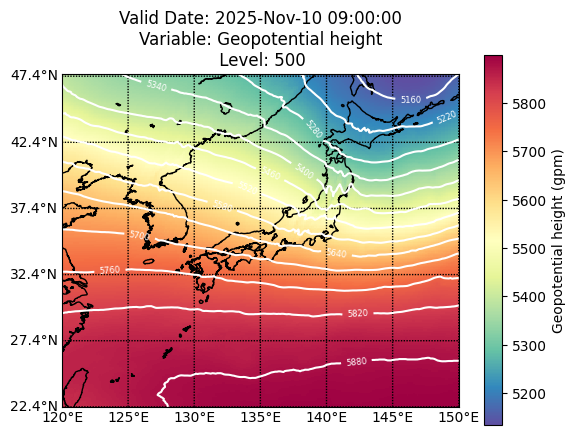

In [187]:

bot_left_lat=lats.min()
bot_left_lon=lons.min()
top_right_lat=lats.max()
top_right_lon=lons.max()
m = Basemap(resolution='i',projection='cyl',\
                llcrnrlon=bot_left_lon,llcrnrlat=bot_left_lat,\
                urcrnrlon=top_right_lon,urcrnrlat=top_right_lat,)

m.drawstates()
m.drawcoastlines()
m.pcolormesh(lons, lats, z500, cmap='Spectral_r')

# Draw latitude lines (parallels) and longitude lines (meridians) with labels
m.drawparallels(np.arange(bot_left_lat, top_right_lat+1, 5), labels=[1,0,0,0], fontsize=10)
m.drawmeridians(np.arange(bot_left_lon, top_right_lon+1, 5), labels=[0,0,0,1], fontsize=10)

cb = plt.colorbar()
cb.set_label(z500_msg.name + " (" + z500_msg.units + ")")

# Add 500 mb Geopotential Height Contours on top
CS = m.contour(lons,lats,z500,colors='white',levels=np.arange(0,6000,60))
plt.clabel(CS, inline=1, fontsize=6,fmt='%1.0f')

validDate = z500_msg.validDate
plt.title('Valid Date: '+validDate.strftime('%Y-%b-%d %H:%M:%S')+'\n'+
              'Variable: '+z500_msg.name+"\n Level: "+str(z500_msg.level))
figure_num += 1

Text(0.5, 1.0, 'Valid at: 2025-Nov-10 09:00:00 Geopotential height 500mb')

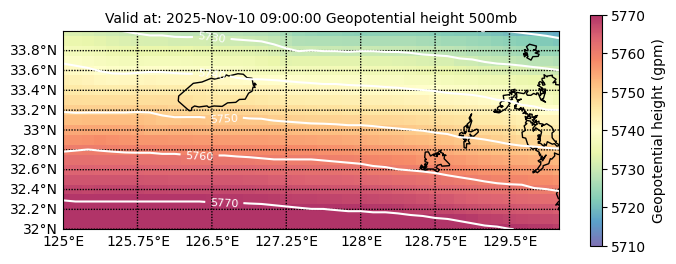

In [188]:
zoom_bot_left_lon  = 125.
zoom_bot_left_lat  = 32.
zoom_top_right_lon = 130.0
zoom_top_right_lat = 34.

# Set up figure with a custom size that matches the aspect ratio of your zoom box
plt.figure(figsize=(8, 6))

m = Basemap(resolution='i', projection='cyl',\
            llcrnrlon=zoom_bot_left_lon, llcrnrlat=zoom_bot_left_lat,\
            urcrnrlon=zoom_top_right_lon, urcrnrlat=zoom_top_right_lat)

m.drawstates()
m.drawcoastlines()

# Set the gridline intervals
m.drawparallels(np.arange(32.0, 34., 0.2), labels=[1,0,0,0], fontsize=10)
m.drawmeridians(np.arange(125., 130.1, 0.75), labels=[0,0,0,1], fontsize=10)

# Crop the matplotlib viewport strictly to the zoomed box
plt.xlim(zoom_bot_left_lon, zoom_top_right_lon)
plt.ylim(zoom_bot_left_lat, zoom_top_right_lat)

# Plot background
im = plt.pcolormesh(lons, lats, z500, cmap='Spectral_r', vmax=5770, vmin=5710, alpha=0.8)

# Adjust the colorbar: 'shrink' scales its length, 'aspect' scales its thickness
plt.colorbar(im, label='Geopotential height (gpm)', shrink=0.5, aspect=20)

# Add 500 mb Geopotential Height Contours on top
CS = m.contour(lons,lats,z500,colors='white',levels=np.arange(0,6000,10))
plt.clabel(CS, inline=1, fontsize=8,fmt='%1.0f')
validDate = z500_msg.validDate
plt.title('Valid at: '+validDate.strftime('%Y-%b-%d %H:%M:%S')+ ' '+
          z500_msg.name+ ' '+str(z500_msg.level)+'mb',fontsize=10)

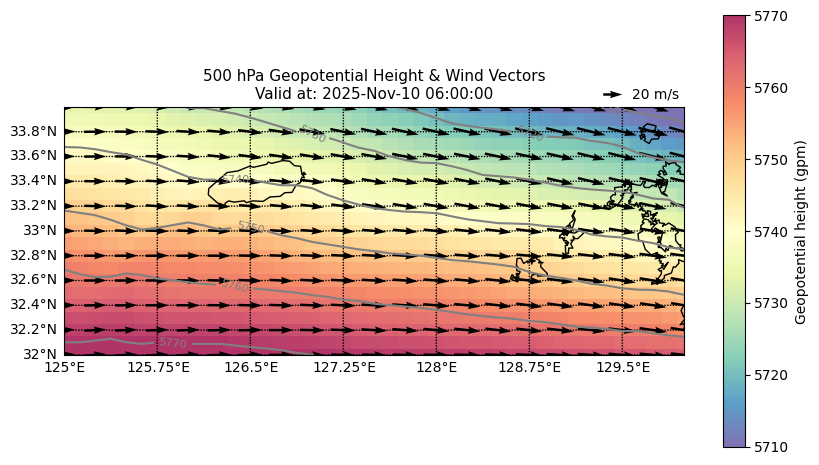

In [185]:
# Get U and V wind components at 500 hPa matching the 6-hour forecast
u_msg = grbs.select(name='U component of wind', level=500, forecastTime=6)[0]
v_msg = grbs.select(name='V component of wind', level=500, forecastTime=6)[0]

u_wind = u_msg.values
v_wind = v_msg.values

# Set up the zoomed map
plt.figure(figsize=(10, 8))
m_wind = Basemap(resolution='i', projection='cyl',\
                 llcrnrlon=zoom_bot_left_lon, llcrnrlat=zoom_bot_left_lat,\
                 urcrnrlon=zoom_top_right_lon, urcrnrlat=zoom_top_right_lat)

m_wind.drawstates()
m_wind.drawcoastlines()

# Gridlines
m_wind.drawparallels(np.arange(32.0, 34., 0.2), labels=[1,0,0,0], fontsize=10)
m_wind.drawmeridians(np.arange(125., 130.1, 0.75), labels=[0,0,0,1], fontsize=10)

# Set strictly zoomed boundaries
plt.xlim(zoom_bot_left_lon, zoom_top_right_lon)
plt.ylim(zoom_bot_left_lat, zoom_top_right_lat)

# Plot Geopotential height background
plt.pcolormesh(lons, lats, z500, cmap='Spectral_r', vmax=5770, vmin=5710, alpha=0.8)
plt.colorbar(label='Geopotential height (gpm)', shrink=0.7, aspect=20)

# Plot Geopotential height contours
CS = m_wind.contour(lons, lats, z500, colors='grey', levels=np.arange(5710, 5771, 10))
plt.clabel(CS, inline=1, fontsize=8, fmt='%1.0f')

# Decimate the grid coordinates to avoid cluttering the plot with too many vectors
skip = 2
x, y = m_wind(lons, lats)

# Plot wind vectors using quiver
Q = m_wind.quiver(x[::skip, ::skip], y[::skip, ::skip], u_wind[::skip, ::skip], v_wind[::skip, ::skip],
                  pivot='middle', color='black', scale=650, width=0.004)

# Add quiver key
plt.quiverkey(Q, 0.9, 1.05, 20, '20 m/s', labelpos='E', coordinates='axes')

validDate = z500_msg.validDate
plt.title('500 hPa Geopotential Height & Wind Vectors\nValid at: ' + validDate.strftime('%Y-%b-%d %H:%M:%S'), fontsize=11)
plt.show()

### Customizing Figure Orientation and Colorbar Dimensions

* **Landscape Layout**: Modified using `figsize=(width, height)` where `width > height` (e.g., `figsize=(12, 6)`).
* **Colorbar Scale**: Controlled with the `shrink` parameter (e.g., `shrink=0.6` to make it shorter) and the `aspect` parameter (e.g., `aspect=15` or higher to make it thinner) inside `plt.colorbar()`.

some backup lines below

In [114]:
variables = ['Temperature','Relative humidity','Vertical Velocity']
figure_num = 1
for v in variables:
    # find first grb message with a matching name
    grb = grbs.select(name='V component of wind')[0]  # the number in brackets is the level [0] surface, [-1] model top
    # Print grb - there is some good info in here, like the model level
    print(grb)
    grb

3:V component of wind:m s**-1 (instant):regular_ll:isobaricInhPa:level 100000.0 Pa:fcst time 0 hrs:from 202511100000
3:V component of wind:m s**-1 (instant):regular_ll:isobaricInhPa:level 100000.0 Pa:fcst time 0 hrs:from 202511100000
3:V component of wind:m s**-1 (instant):regular_ll:isobaricInhPa:level 100000.0 Pa:fcst time 0 hrs:from 202511100000


In [99]:
grbs.seek(0) #(go back to top of file)
for grb in grbs:
    grb
    #print(grb) # Print an inventory of the file

In [87]:
G = grbs[55]
G
G.name

'Geopotential height'

In [89]:
G.analDate
G.validDate
G.fcstimeunits
G.projparams

{'a': 6371229, 'b': 6371229, 'proj': 'longlat'}

In [90]:
data, lats, lons = G.data()